In [1]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parents[2]

sys.path.append(str(PROJECT_ROOT))

# from src.solvers.cavity3d import solve_cavity_3d


plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["image.origin"] = "lower"

In [ ]:
import torch

from flow.cavity_driven_3d.solver import CavitySolver3D

solver = CavitySolver3D()

solver.solve()

print(torch.isnan(solver.u).any())
print(torch.isnan(solver.v).any())
print(torch.isnan(solver.w).any())
print(torch.isnan(solver.p).any())

print(torch.isinf(solver.u).any())
print(torch.isinf(solver.v).any())
print(torch.isinf(solver.w).any())
print(torch.isinf(solver.p).any())

Using: cpu
tensor(False)
tensor(False)
tensor(False)
tensor(False)
tensor(False)
tensor(False)
tensor(False)
tensor(False)


In [5]:
info = solver.diagnostics()

print(info["cfl"])

print(info["max_div"])
print(info["mean_div"])

0.031000003218650818
15.5
0.034803356975317


In [66]:
assert torch.allclose(
    solver.u[1:-1, -1, 1:-1],
    torch.full_like(
        solver.u[1:-1, -1, 1:-1],
        solver.lid_velocity,
    ),
)

In [67]:
assert torch.allclose(
    solver.u[0, :, :],
    torch.zeros_like(solver.u[0, :, :]),
)

assert torch.allclose(
    solver.u[-1, :, :],
    torch.zeros_like(solver.u[-1, :, :]),
)

assert torch.allclose(
    solver.u[:, :, 0],
    torch.zeros_like(solver.u[:, :, 0]),
)

assert torch.allclose(
    solver.u[:, :, -1],
    torch.zeros_like(solver.u[:, :, -1]),
)


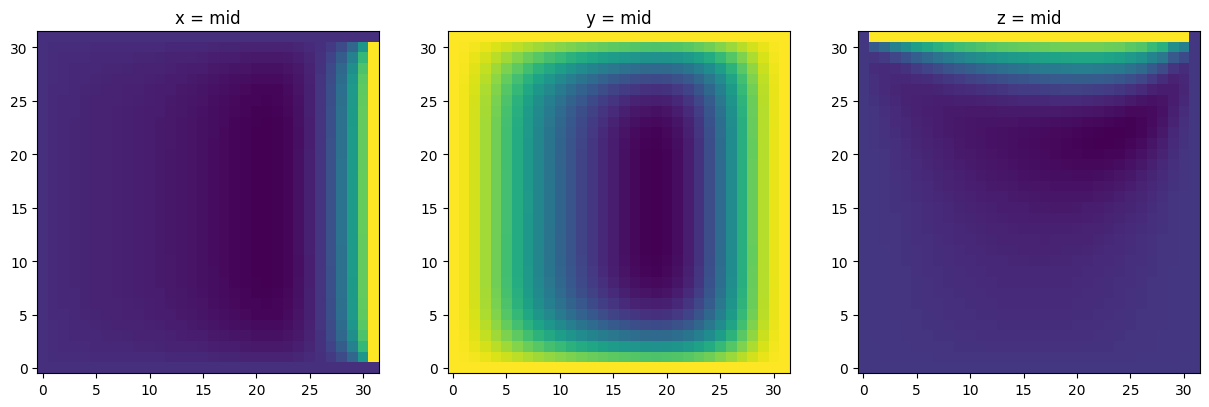

In [13]:
mid_x = solver.u.shape[0] // 2
mid_y = solver.u.shape[1] // 2
mid_z = solver.u.shape[2] // 2

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(solver.u[mid_x, :, :].cpu().T, origin="lower")
ax[0].set_title("x = mid")

ax[1].imshow(solver.u[:, mid_y, :].cpu().T, origin="lower")
ax[1].set_title("y = mid")

ax[2].imshow(solver.u[:, :, mid_z].cpu().T, origin="lower")
ax[2].set_title("z = mid")

plt.show()

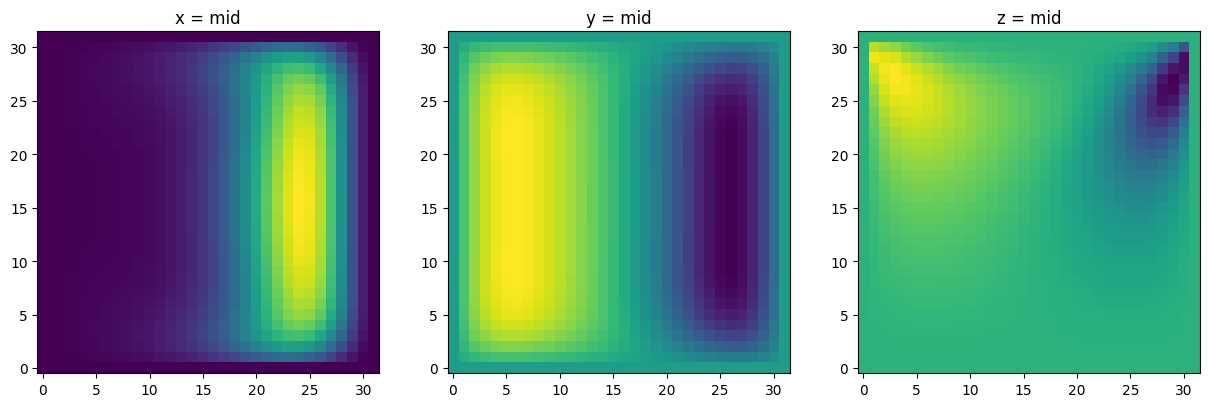

In [16]:
mid_x = solver.v.shape[0] // 2
mid_y = solver.v.shape[1] // 2
mid_z = solver.v.shape[2] // 2

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(solver.v[mid_x, :, :].T, origin="lower")
ax[0].set_title("x = mid")

ax[1].imshow(solver.v[:, mid_y, :].T, origin="lower")
ax[1].set_title("y = mid")

ax[2].imshow(solver.v[:, :, mid_z].T, origin="lower")
ax[2].set_title("z = mid")

plt.show()

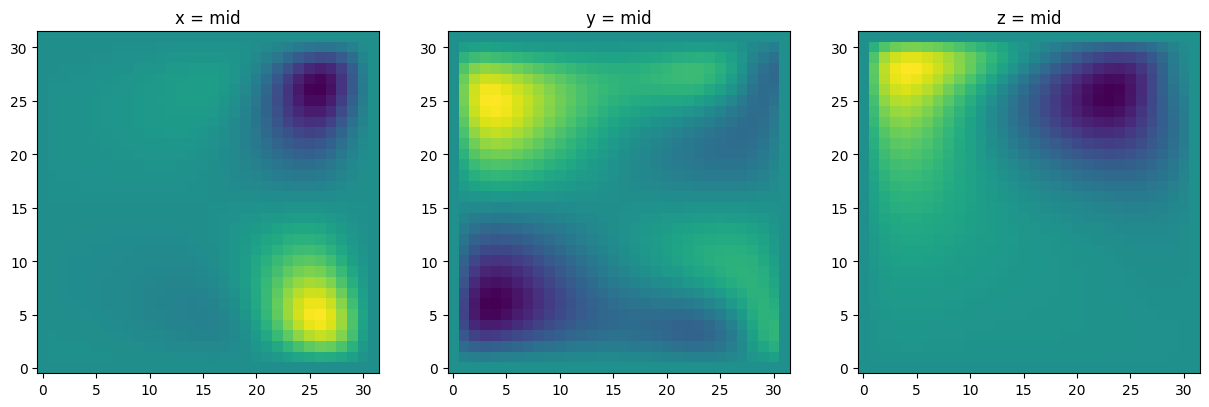

In [17]:
mid_x = solver.w.shape[0] // 2
mid_y = solver.w.shape[1] // 2
mid_z = solver.w.shape[2] // 2

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(solver.w[mid_x, :, :].cpu().T, origin="lower")
ax[0].set_title("x = mid")

ax[1].imshow(solver.w[:, mid_y, :].cpu().T, origin="lower")
ax[1].set_title("y = mid")

ax[2].imshow(solver.w[:, :, mid_z].cpu().T, origin="lower")
ax[2].set_title("z = mid")

plt.show()

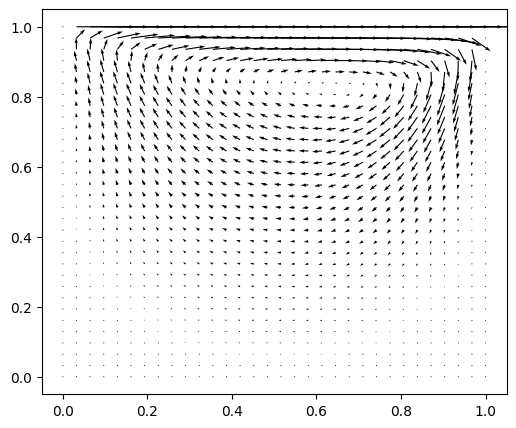

In [19]:
X, Y = torch.meshgrid(
    solver.x,
    solver.y,
    indexing="ij"
)
plt.quiver(
    X,
    Y,
    solver.u[:,:,mid],
    solver.v[:,:,mid]
)

In [20]:
left = solver.u[:,:,8]

right = solver.u[:,:,23]

print(
    torch.mean(
        torch.abs(left-right)
    )
)

tensor(1.0680e-07)


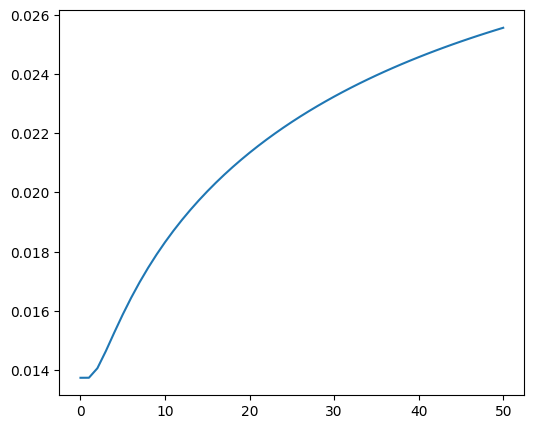

In [21]:
ke = []

for u,v,w in zip(
    solver.snapshots["u"],
    solver.snapshots["v"],
    solver.snapshots["w"],
):

    ke.append(
        0.5*torch.mean(
            u**2+v**2+w**2
        )
    )

plt.plot(ke)

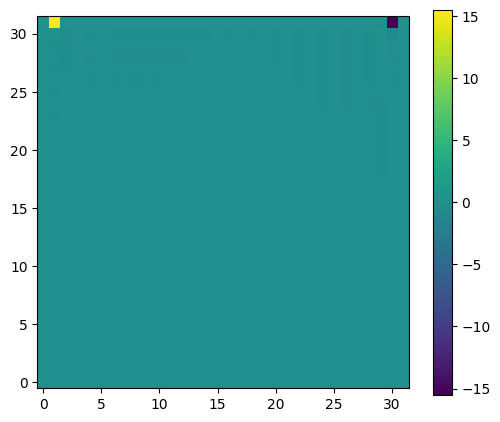

In [72]:

from src.operators.vector_calculus import divergence


div = divergence(
    solver.u,
    solver.v,
    solver.w,
    solver.dx,
    solver.dy,
    solver.dz,
)
plt.imshow(div[:, :, mid].cpu().T, origin="lower")
plt.colorbar()

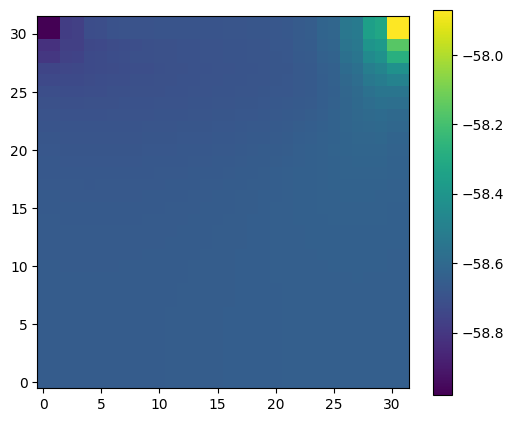

In [23]:
plt.imshow(
    solver.p[:,:,mid].cpu().T,
    origin="lower"
)

plt.colorbar()

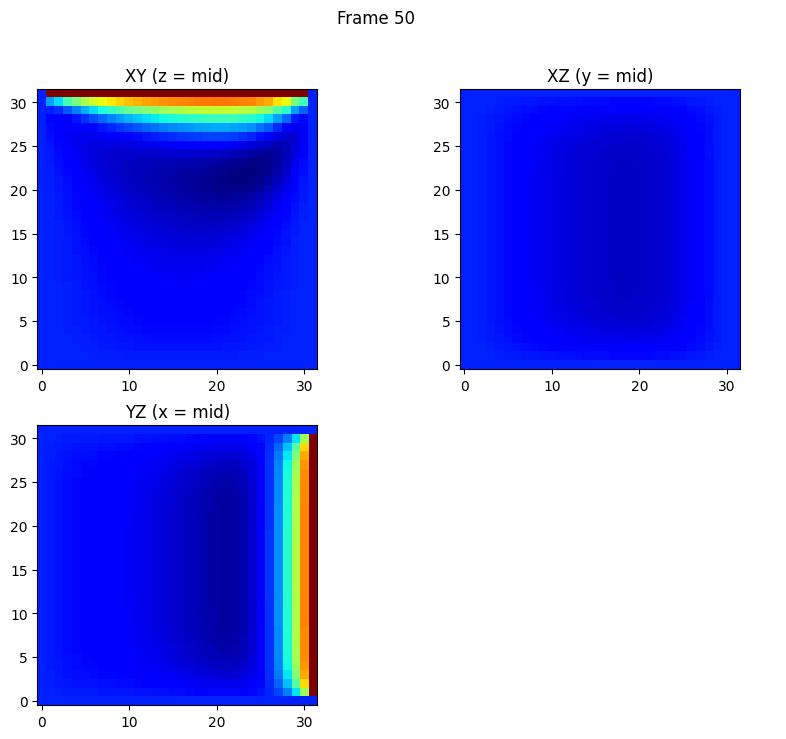

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

u_hist = solver.snapshots["u"]

mid_x = solver.Nx // 2
mid_y = solver.Ny // 2
mid_z = solver.Nz // 2

fig, ax = plt.subplots(2,2, figsize=(10,8))

ax = ax.ravel()

vmin = min(u.min() for u in u_hist)
vmax = max(u.max() for u in u_hist)

im_xy = ax[0].imshow(
    u_hist[0][:,:,mid_z].T,
    origin="lower",
    cmap="jet",
    animated=True,
    vmin=vmin,
    vmax=vmax
)

im_xz = ax[1].imshow(
    u_hist[0][:,mid_y,:].T,
    origin="lower",
    cmap="jet",
    animated=True,
    vmin=vmin,
    vmax=vmax
)

im_yz = ax[2].imshow(
    u_hist[0][mid_x,:,:].T,
    origin="lower",
    cmap="jet",
    animated=True,
    vmin=vmin,
    vmax=vmax
)

ax[0].set_title("XY (z = mid)")
ax[1].set_title("XZ (y = mid)")
ax[2].set_title("YZ (x = mid)")

ax[3].axis("off")



def update(frame):

    u = u_hist[frame]

    im_xy.set_array(u[:,:,mid_z].cpu().T)

    im_xz.set_array(u[:,mid_y,:].cpu().T)

    im_yz.set_array(u[mid_x,:,:].cpu().T)

    fig.suptitle(f"Frame {frame}")

    return (
        im_xy,
        im_xz,
        im_yz,
    )

ani = FuncAnimation(
    fig,
    update,
    frames=len(u_hist),
    interval=100,
    blit=True,
)

HTML(ani.to_jshtml())

In [63]:
def plot_streamlines(
    u,
    v,
    x,
    y,
    z,
    plane="xy",
    index= Nz // 2,
    ax = None
):
    """
    Plots streamlines for a given velocity field in a specified plane.

    Parameters:
    - u: 3D tensor of x-velocity components.
    - v: 3D tensor of y-velocity components.
    - x: 1D array of x-coordinates.
    - y: 1D array of y-coordinates.
    - plane: The plane to plot ('xy', 'xz', or 'yz').
    - index: The index along the third dimension to slice for the specified plane.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))

    if plane == "xy":
        U = u[:, :, index].cpu().numpy()
        V = v[:, :, index].cpu().numpy()
        speed = np.sqrt(U**2 + V**2)

        ax.streamplot(
            x,
            y,
            U.T,
            V.T,
            density=2.0,
            linewidth=1.2,
            arrowsize=1.2,
            color=speed.T,
            cmap = 'viridis'
        )
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_title(f"Velocity Streamlines (z = {index})")
    
    elif plane == "xz":
        U = u[:, index, :].cpu().numpy()
        W = w[:, index, :].cpu().numpy()
        speed = np.sqrt(U**2 + W**2)

        ax.streamplot(
            x,
            z,
            U.T,
            W.T,
            density=2.0,
            linewidth=1.2,
            arrowsize=1.2,
            color=speed.T,
            cmap = 'viridis'
        )
        ax.set_xlabel("x")
        ax.set_ylabel("z")
        ax.set_title(f"Velocity Streamlines (y = {index})")
    
    elif plane == "yz":
        V = v[index, :, :].cpu().numpy()
        W = w[index, :, :].cpu().numpy()
        speed = np.sqrt(V**2 + W**2)

        ax.streamplot(
            y,
            z,
            V.T,
            W.T,
            density=2.0,
            linewidth=1.2,
            arrowsize=1.2,
            color=speed.T,
            cmap = 'viridis'
        )
        ax.set_xlabel("y")
        ax.set_ylabel("z")
        ax.set_title(f"Velocity Streamlines (x = {index})")

    else:
        raise ValueError("Invalid plane specified. Choose from 'xy', 'xz', or 'yz'.")

    ax.axis("equal")


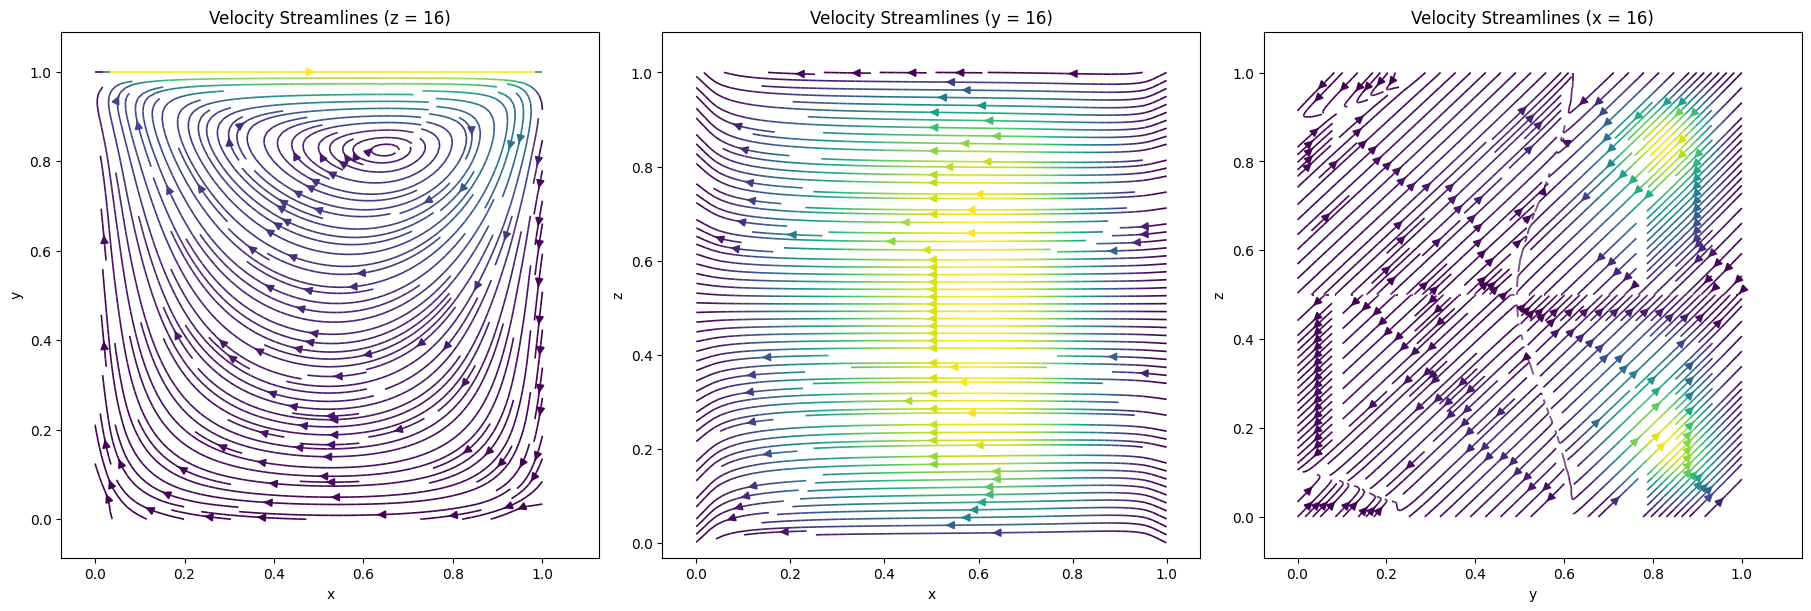

In [64]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6),
    constrained_layout=True
)
plot_streamlines(
    solver.u,
    solver.v,
    solver.results()["x"].numpy(),
    solver.results()["y"].numpy(),
    solver.results()["z"].numpy(),
    plane="xy",
    index=solver.Nz // 2,
    ax=axes[0],
)

plot_streamlines(
    solver.u,
    solver.w,
    solver.results()["x"].numpy(),
    solver.results()["y"].numpy(),
    solver.results()["z"].numpy(),
    plane="xz",
    index=solver.Ny // 2,
    ax=axes[1],
)
plot_streamlines(
    solver.v,
    solver.w,
    solver.results()["x"].numpy(),
    solver.results()["y"].numpy(),
    solver.results()["z"].numpy(),
    plane="yz",
    index=solver.Ny // 2,
    ax = axes[2]
)

plt.show()